## Import the Relevant Libraries

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_validate
from sklearn.preprocessing import MinMaxScaler

## Create a Directory to Store the Results

In [3]:
if not os.path.exists('res'):
  os.makedirs('res')

## Load the Data into a DataFrame

In [4]:
df = pd.read_csv("data/Advertising.csv")
print(df.shape)
df.head(10)

(200, 4)


,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,12.0
3,151.5,41.3,58.5,16.5
4,180.8,10.8,58.4,17.9
5,8.7,48.9,75.0,7.2
6,57.5,32.8,23.5,11.8
7,120.2,19.6,11.6,13.2
8,8.6,2.1,1.0,4.8
9,199.8,2.6,21.2,15.6


First let's check the data types in each column, to verify that they are indeed floats. Also need to ascertain whether there are any missing values.

In [5]:
df.dtypes

TV           float64
Radio        float64
Newspaper    float64
Sales        float64
dtype: object

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   Radio      200 non-null    float64
 2   Newspaper  200 non-null    float64
 3   Sales      200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB


In this linear regression, the columns "TV", "Radio" and "Newspaper" will be our predictor variables (features), with "Sales" being the target variable. The three predictor variables are expressed in thousands of euro, while Sales is expressed in thousands of units sold. Let's split the data into a DataFrame of predictor variables and a Series of the single target variable.

In [7]:
featureNames = df.columns[:3]
targetName = df.columns[3]
X3 = df[featureNames]
y = df[targetName]

## Plot Sales vs Total Advertising Spend

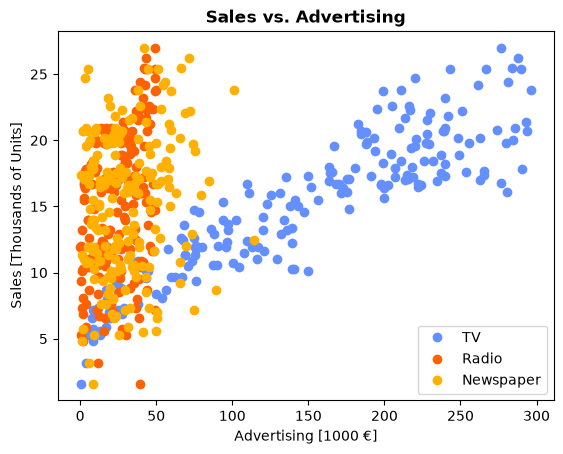

In [8]:
ibm5col = {"trueBlue": "#648FFF", "mauve": "#785EF0", "hotPink": "#DC267F", "orange": "#FE6100", "mustard": "#FFB000"}
colours = ['trueBlue', 'orange', 'mustard']
colourSet = dict(zip(featureNames, colours))

fig, ax = plt.subplots()
ax.set_xlabel('Advertising [1000 €]')
ax.set_ylabel('Sales [Thousands of Units]')
title = ax.set_title("Sales vs. Advertising", weight="bold")

# Plot Sales vs. Advertising spend per channel

for featureName in colourSet:
  colour = ibm5col[colourSet[featureName]]
  ax.plot(X3[featureName], y, 'o', color = colour, label = featureName)

lines, labels = ax.get_legend_handles_labels()
ax.legend(lines, labels, loc = 'lower right')
plt.savefig('res/data.png', bbox_inches = 'tight')
plt.show()

The scatterplot shows what appears to be a positive linear relationship between advertising expenditure and TV sales. In the case of Radio and Newspaper things are a little less clear, although some amount of postive correlation can be seen in relation to increased expenditure on Radio advertising. This scatterplot also shows the data is fairly well clustered, with no obvious outliers.

## Correlation Map for the three Features and Target Variable

Next, let's investigate any potential correlation between the variables (between predictors and between individual predictors and target) using three well known measures of correlation: The "Pearson Correlation Coefficient", the "Kendall Rank Correlation Coefficient", and "Spearman's Rank Correlation Coefficient". A heatmap is used in all three cases to visualise the pairwise interactions of the variables with respect to these measure. (Note that based on the previous scatterplot, it is clear that there is only potential for positive correlation between the variables, and so the heatmap will take 0 as minimum value for the colour gradient, and 1 as a maximum.)

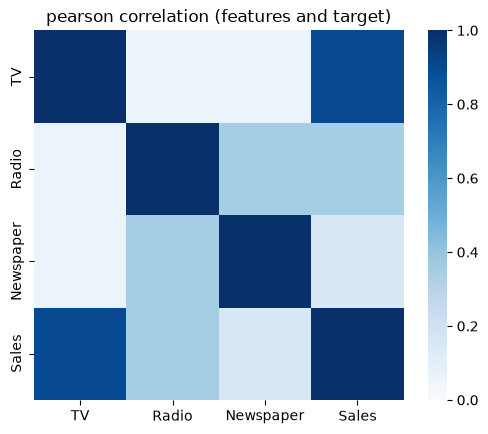

,TV,Radio,Newspaper,Sales
TV,1.000000,0.054809,0.056648,0.901208
Radio,0.054809,1.000000,0.354104,0.349631
Newspaper,0.056648,0.354104,1.000000,0.157960
Sales,0.901208,0.349631,0.157960,1.000000


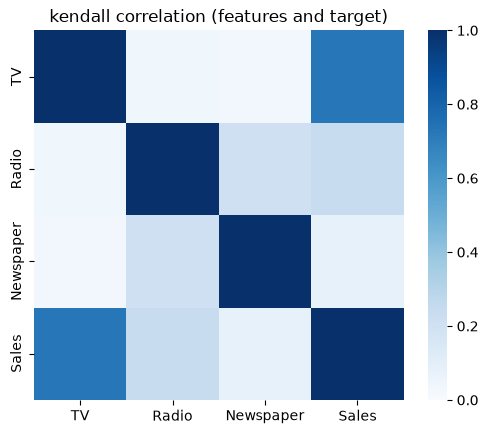

,TV,Radio,Newspaper,Sales
TV,1.000000,0.041202,0.034156,0.727994
Radio,0.041202,1.000000,0.207077,0.241035
Newspaper,0.034156,0.207077,1.000000,0.081295
Sales,0.727994,0.241035,0.081295,1.000000


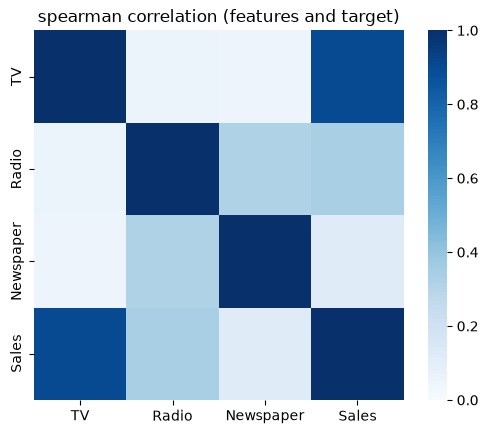

,TV,Radio,Newspaper,Sales
TV,1.000000,0.056123,0.050840,0.900996
Radio,0.056123,1.000000,0.316979,0.339949
Newspaper,0.050840,0.316979,1.000000,0.123027
Sales,0.900996,0.339949,0.123027,1.000000


In [18]:
cmap = sns.color_palette("Blues", as_cmap=True)
for method in ('pearson', 'kendall', 'spearman'):
  Corr = df.corr(method = method)
  hm = sns.heatmap(Corr, square = True, vmin = 0, vmax = 1, cmap = cmap)
  plt.title(f"{method} correlation (features and target)")
  fig = hm.get_figure()
  fig.savefig(f"res/{method}CorrHeatmap.png")
  plt.show()
  display(Corr)

All three heatmaps tell a similar story: There is a strong positive correlation between TV advertsing expenditure and Sales (A Pearson Correlation Coefficient of over 0.9), with only a weak to moderate positive correlation between Radio advertising expenditure and Sales (Pearson Coefficient of ~0.34), and little to no correlation between Newspaper advertising expenditure and Sales (Pearson Coefficient of ~0.16). A weak to moderate correlation can also be seen between the Radio and Newspaper features, with a Pearson Correlation Coefficient of 0.35. As this is not a particularly strong correlation, it is fine to include both of these predictor variables in the linear regression model simultaneously.

## Initialize the Model and Choose the Score Metric

Let's use the LinearRegression model from Scikit learn, with the negative of the mean squared error and R squared coefficient being used to evaluate the results. The ***negative*** of the mean squared error is being used so that increasing this value is associated with improving the model.

In [19]:
model = LinearRegression(fit_intercept=True)
metric = ('neg_mean_squared_error', 'r2')

## Forward Selection 1 - Getting the Next Best Feature

We identify two operations:

1. Finding the loss metric for each of a candidate set of features to be added to the model, and returning the feature with the largest metric. A 5-fold cross validation will be used to find the loss metric for each new feature.
2. Add one feature at a time to the model in a "greedy" fashion. Adding the feature that maximizes the loss metric, as calculated in step 1.

The following Python function `findNextBestFeature()` provides operation 1., and the next block of python provides operation 2.

In [20]:
def findNextBestFeature(X,foundFeatures):   
  nP = X.shape[1] # number of columns in X
  allFeatures = list(X) # returns the column headers in a list
  featuresToSearch = set(allFeatures) - set(foundFeatures)
  maxScore = -np.inf # Initialize the max score at negative infinity
    
  for feature in featuresToSearch: # loop over all remaining columns (features) in X
    trialFeatures = set(foundFeatures)
    trialFeatures.add(feature) # Add this feature to the existing features
    XcolSubset = X.loc[:,list(trialFeatures)] # all rows and just the trial features
    scores = cross_validate(model, XcolSubset, y, cv = 5, scoring = metric, return_train_score = True)
    score = np.mean(scores['test_neg_mean_squared_error'])
    trialFeatures.remove(feature) # remove the current feature from the trialFeatures, to be ready for the next candidate feature
  
    if score > maxScore: # identify the largest score and its associated feature
      maxScore = score
      metricsForAddedFeature = scores
      bestFeatureFound = feature

  trialFeatures.add(bestFeatureFound)
  print(f"Selected {bestFeatureFound} so current features are {trialFeatures} with score {maxScore}.")

  return maxScore, bestFeatureFound, metricsForAddedFeature

## Forward Selection 2 - Iterating over the Search for the Next Best Feature

Now use `findNextBestFeature` to iterate through the list of features and to keep track of the scores.

In [21]:
def prioritiseFeatures(X):
  nP = X.shape[1]
  scoreHistory = dict()
  foundFeatures = list()

  for i in range(nP): # loop over all columns (features) in X
    score, bestFeatureFound, metricsForAddedFeature = findNextBestFeature(X, foundFeatures)
    foundFeatures.append(bestFeatureFound)
    scoreHistory[bestFeatureFound] = metricsForAddedFeature
      
  return foundFeatures, scoreHistory

## Preparing a DataFrame to Make Feature Analysis Easier

Parse the scores and map into a DataFrame for convenient analysis. In the case of fitting time and scoring time, we will take the mean of the results across the 5 cross validation sets. In the case of the negative mean squared error and the r squared coefficient in both testing and training, we will report a range of values. That is, we will retain the minimum and maximum values seen across the 5 cross validation sets.

In [22]:
def parseToDF(foundFeatures, scoreHistory):
  scoreList = []
  for feature in foundFeatures:
    scoreDS = scoreHistory[feature]
    fitTime = np.mean(scoreDS["fit_time"])
    scoreTime = np.mean(scoreDS["score_time"])
    testNegMSE = (np.min(scoreDS["test_neg_mean_squared_error"]), np.max(scoreDS["test_neg_mean_squared_error"]))
    trainNegMSE = (np.min(scoreDS["train_neg_mean_squared_error"]), np.max(scoreDS["train_neg_mean_squared_error"]))
    testR2 = (np.min(scoreDS["test_r2"]), np.max(scoreDS["test_r2"]))
    trainR2 = (np.min(scoreDS["train_r2"]), np.max(scoreDS["train_r2"]))
    record = {'feature': feature, 'fit_time': fitTime, 'score_time': scoreTime,
              'test_neg_mean_squared_error': testNegMSE, 'train_neg_mean_squared_error': trainNegMSE,
              'test_r2': testR2, 'train_r2': trainR2}
    scoreList.append(record)
  
  scoresDf = pd.DataFrame.from_dict(scoreList)
  return scoresDf

## Derive the Scores DataFrame for a Given Feature Matrix X

In [23]:
def deriveScoresDf(X):
  foundFeatures, scoreHistory = prioritiseFeatures(X)
  scoresDf = parseToDF(foundFeatures, scoreHistory)
  return scoresDf

We will now apply this function to the advertising data.

In [24]:
scoresDf3 = deriveScoresDf(X3)
display(scoresDf3[["feature", "test_neg_mean_squared_error", "test_r2"]])

Selected TV so current features are {'TV'} with score -5.345456101166027.
Selected Radio so current features are {'TV', 'Radio'} with score -2.845231593418053.
Selected Newspaper so current features are {'Newspaper', 'TV', 'Radio'} with score -2.8582430099910097.


,feature,test_neg_mean_squared_error,test_r2
0,TV,"(-7.324310374422005, -3.9369810322191725)","(0.7603440777107349, 0.8390841989031752)"
1,Radio,"(-4.718440611471555, -1.8510139478354657)","(0.8456097326980663, 0.9322678692463672)"
2,Newspaper,"(-4.72039259225367, -1.8510521207093062)","(0.8455458626911012, 0.9317779087301498)"


## Analysis

Note that there is a lot of overlap between the test scores for `TV + Radio` and `TV + Radio + Newspaper`
(the minimum and maximum for each class of metric are very similar). Hence, `Newspaper` adds almost
no value to the model, so we do not include this feature.

## Interaction Terms

To add an interaction terms, we need to multiply two features in that interaction. However, this can
introduce scaling difficulties (known as structured correlation, will happen as all variables in this dataset are positive) so we scale the features so that all features (including the new
interaction terms) will have the same scaling. After scaling, the minimum of every variable will be 0, and the maximum will be 1.

In [25]:
X4 = X3.copy()
X4["TV:Radio"] = X4["TV"] * X4["Radio"]
X4["TV:Newspaper"] = X4["TV"] * X4["Newspaper"]
X4["Radio:Newspaper"] = X4["Radio"] * X4["Newspaper"]

scaler = MinMaxScaler()
scaler.fit(X4)
X4scaled = pd.DataFrame(scaler.transform(X4), columns  = X4.columns, index = X4.index)

## Generate the scores for X4 (with the interaction terms)

In [26]:
scoresDf4 = deriveScoresDf(X4scaled)
display(scoresDf4[["feature", "test_neg_mean_squared_error", "test_r2"]])

Selected TV so current features are {'TV'} with score -5.34545610116603.
Selected TV:Radio so current features are {'TV:Radio', 'TV'} with score -2.6144559094182798.
Selected Radio so current features are {'TV:Radio', 'TV', 'Radio'} with score -2.5562280152128114.
Selected Radio:Newspaper so current features are {'Radio:Newspaper', 'TV:Radio', 'TV', 'Radio'} with score -2.567574250052337.
Selected Newspaper so current features are {'Newspaper', 'Radio:Newspaper', 'TV:Radio', 'TV', 'Radio'} with score -2.5811946679113262.
Selected TV:Newspaper so current features are {'Newspaper', 'TV:Newspaper', 'Radio:Newspaper', 'TV:Radio', 'TV', 'Radio'} with score -2.7042492290875764.


,feature,test_neg_mean_squared_error,test_r2
0,TV,"(-7.3243103744220095, -3.9369810322191747)","(0.7603440777107348, 0.8390841989031753)"
1,TV:Radio,"(-3.6950482886403733, -1.847993519165616)","(0.8790957564264388, 0.9377953274242407)"
2,Radio,"(-3.9297847588259067, -1.751389612982819)","(0.8714150353235077, 0.9410470781968048)"
3,Radio:Newspaper,"(-3.9233235509538487, -1.7558936127104494)","(0.8716264500031871, 0.9408954706151585)"
4,Newspaper,"(-3.9080346002837105, -1.7473068140356578)","(0.8721267138350535, 0.9411845078842289)"
5,TV:Newspaper,"(-4.263113099912714, -1.989117169339766)","(0.8605083278077692, 0.9330450129016321)"


## Analysis

Interestingly, we see that using the predictor "TV" together with the interaction term "TV:Radio" to predict "Sales" leads to the best results - better than when using "TV" and "Radio" to predict the target. Adding in further predictors and interaction terms after this point does not increase the explanatory power of the model by a significant amount. This can be seen by the fact that on the test data, both the negative of the mean squared error and the R squared coefficient stay approximately constant when adding more terms.

Thus by this analysis, the model should be: "Sales" ~ "TV" + "TV:Radio"